# AP 155 Lab Exercise
---
## Exercise 8: Minimization

_Instructions_: 
- **Report figure:** A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm.  
- **Report discussion:** What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Hernando, Claire Marie M.
- _Student No._: 2024-12904
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

![Plot of the original functions and their derivatives](2by2plot.png) <img src="../Claire/Exercise 8/2by2plot.jpg" width=45%>
***Figure 2** shows a 2 by 2 figure plot, with the upper row containing the plot of the actual functions, and the lower row containing the plot of their derivatives. This also includes markers to plot the found local extrema by the golden section search algorithm.*


### Report discussion

**What happens if a number other than the golden ratio is used to perform the golden section search algorithm?**

If a number other than the golden ratio is used, the search still works, as long as the two interior points sit symmetrically inside the bracket and the fraction is between 0.5 and 1.0. Each step still throws away a part that cannot contain the minimum, so the interval keeps shrinking and the algorithm converges to the minimum. However, the golden ratio is the one value that places the test points so that, after the interval shrinks, one of the old points lands exactly where a new test point is needed. With any other number, the old point can’t be reused, so two new function evaluations are needed each time, making the process slower. Thus, other numbers still work, but the golden ratio, about 0.618, is the most efficient choice.

### Other comments
None


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Minimization

Consider the following equations:

Eq. 5.91
$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4
$$

Eq. 5.145
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8
$$


1. Plot each of the functions. Get a rough estimate of the local minima and maxima
2. Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.
3. Report figure: A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm. 

### **1.)** Plot each of the functions. Get a rough estimate of the local minima and maxima

In [2]:
# Defining the function
def phi(x):
    return x**4 - 9 * x**3 + 25 * x**2 - 24 * x + 4

def f(x):
    return -x**5 + 4 * x**4 - 4 * x**3 + x**2 * np.exp(x) - 2 * x**2 - 4 * x * np.exp(x) + 8 * x + 4 * np.exp(x) - 8

In [3]:
# Defining tolerance and maximum iterations 
kmax = 1000
tol = 1.e-8

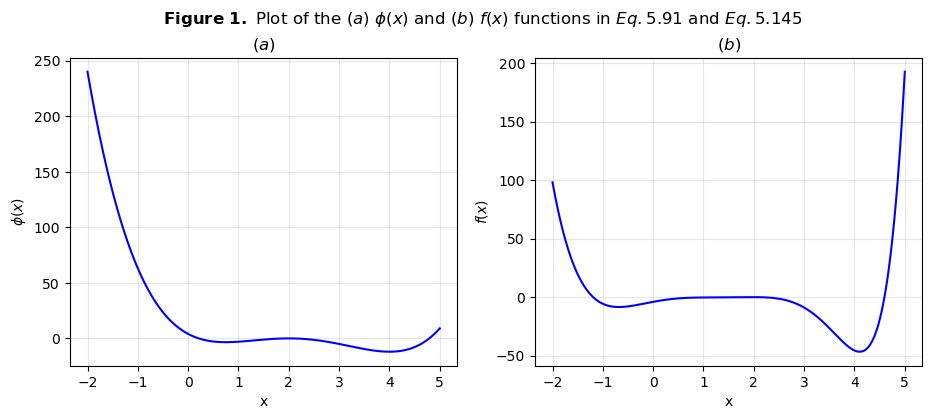

In [4]:
# Plotting to get rough estimate of minima and maxima

fig, axs = plt.subplots(1, 2, figsize=(11,4))
fig.suptitle(r'$\bf{Figure\ 1.}$ Plot of the $\mathit{(a)}$ $\phi(x)$ and $\mathit{(b)}$ $f(x)$ functions in $Eq. 5.91$ and $Eq. 5.145$', y=1.)
x = np.linspace(-2, 5, 800)
axs[0].plot(x, phi(x), 'b-')
axs[0].set_ylabel(r'$\phi(x)$')
axs[0].set_title(r'$(a)$')

x = np.linspace(-2, 5, 800)
axs[1].plot(x, f(x), 'b-')
axs[1].set_ylabel(r'$f(x)$')
axs[1].set_title(r'$(b)$')

for ax in axs:
    ax.set_xlabel('x')
    ax.grid(alpha=0.3)

plt.show()

From Figure 1 above, we can spot the following values to be among its local minima and maxima:

**$\phi(x)$**
- **Local Minima:** 0.75, 4.0
- **Local Maxima:** 2.0

**$f(x)$**
- **Local Minima:** -0.7, 4.2
- **Local Maxima:** 2.0 

### **2.)** Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.

Let's start off with the $\phi(x)$ function in Eq. 5.91.

In [20]:
# Finding local minima of phi(x)
def golden_phi_min(phi, x0, x1):
    varphi = 0.5 * (1 + math.sqrt(5))
    for k in range(1, kmax):
        x2 = x0 + (x1-x0)/(varphi+1)
        x3 = x0 + (x1-x0)*varphi/(varphi+1)

        if phi(x3) < phi(x2):
            x0 = x2
        else:
            x1 = x3

        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)

        if abs(xdiff) < tol:
            break
    else:
        xnew = None
    return xnew 
        
# Naming variables for test points
phi_min_brackets = [(0., 2.0), (3., 5.)] # This can be changed to generate other point/s for local minimum. This also applies for maximum.

# Testing implementation
if __name__ == '__main__':
    for a, b in phi_min_brackets:
        xmin = golden_phi_min(phi, a, b)
        phimin = phi(xmin)
        print(f'Local minimum for phi(x) is x = {xmin:.4f} at phi(x) = {phimin:.4f}.')

Local minimum for phi(x) is x = 0.7500 at phi(x) = -3.4180.
Local minimum for phi(x) is x = 4.0000 at phi(x) = -12.0000.


In [6]:
# Finding local maxima of phi(x)
# Naming variables for test points
a_phi_max, b_phi_max = 1., 3. 

# Solving for local maximum
xmax = golden_phi_min(lambda x: -phi(x), a_phi_max, b_phi_max)
print(f'Local maximum for phi(x) is at x = {xmax:.4f} at phi(x)= {phi(xmax):.4f}.')

Local maximum for phi(x) is at x = 2.0000 at phi(x)= 0.0000.


Next, let's work with the $f(x)$ function in Eq. 5.145.

In [18]:
# Finding local minima of f(x) 
def golden_f_min(f, x0, x1):
    varphi = 0.5 * (1 + math.sqrt(5))
    for k in range(1, kmax):
        x2 = x0 + (x1-x0)/(varphi+1)
        x3 = x0 + (x1-x0)*varphi/(varphi+1)

        if f(x3) < f(x2):
            x0 = x2
        else:
            x1 = x3

        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)

        if abs(xdiff) < tol:
            break
    else:
        xnew = None
    return xnew 

# Naming Variables
f_min_brackets = [(-2., 0.), (3., 5.)]

# Testing implementation 
if __name__ == '__main__':
    for a, b in f_min_brackets:
        xmin = golden_f_min(f, a, b)
        fmin = f(xmin)
        print(f'Local minimum for f(x) is x = {xmin:.4f} at f(x) = {fmin:.4f}.')

Local minimum for f(x) is x = -0.6799 at f(x) = -8.4677.
Local minimum for f(x) is x = 4.1033 at f(x) = -46.6622.


In [8]:
# Finding local maxima of f(x)
# Naming variables for test points
a_f_max, b_f_max = -1., 4.

# Solving for local maximum
xmax = golden_f_min(lambda x: -f(x), a_f_max, b_f_max)
print(f'Local maximum for f(x) is x = {xmax:.4f} at f(x) = {f(xmax):.4f}.')

Local maximum for f(x) is x = 2.0000 at f(x) = -0.0000.


### **3.)** Plotting the actual functions and their derivatives, along with the local extrema found thru golden section search algorithm.

In [9]:
# Finding numerical derivative thru central difference
def numderiv(fun, x, h=1.e-5):
    return (fun(x + h) - fun(x - h))/(2*h)

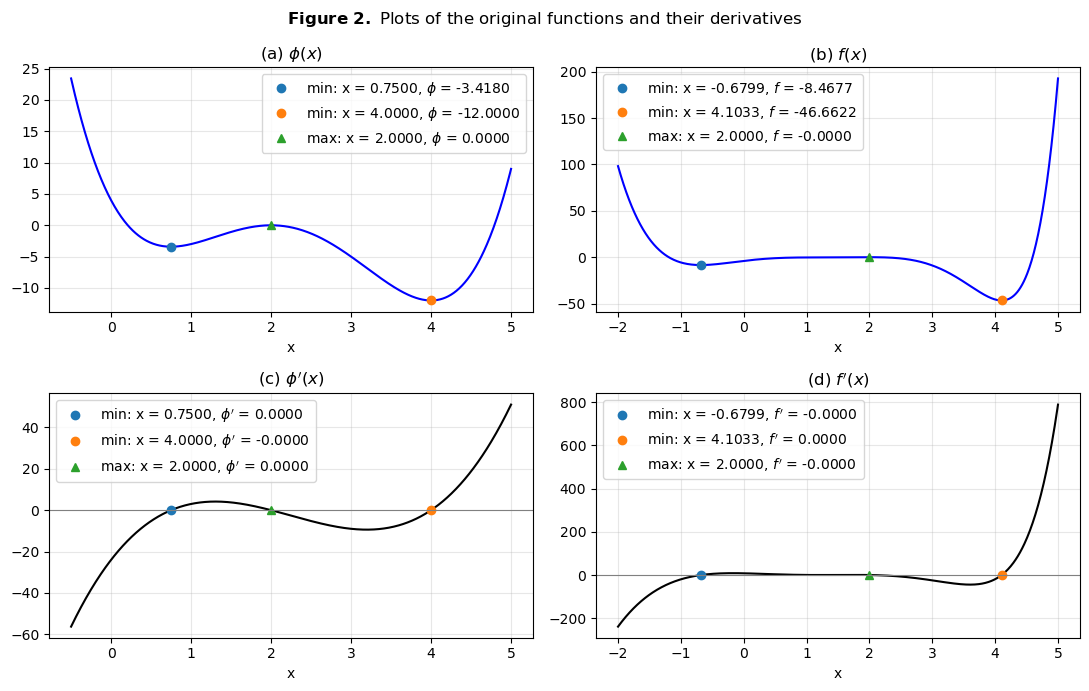

In [28]:
# Plotting the 2 x 2 figure plot
phi_mins = np.array([golden_phi_min(phi, 0., 1.5), golden_phi_min(phi, 3., 5.)])
phi_maxs = np.array([golden_phi_min(lambda x: -phi(x), 1., 3.)])

f_mins = np.array([golden_f_min(f, -2., 0.), golden_f_min(f, 3., 5.)])
f_maxs = np.array([golden_f_min(lambda x: -f(x), 1., 3.)])

fig, axs = plt.subplots(2, 2, figsize=(11, 7))
fig.suptitle(r'$\bf{Figure\ 2.}$ Plots of the original functions and their derivatives')

# For the 1st column
x = np.linspace(-0.5, 5, 800)
axs[0,0].plot(x, phi(x), 'b-')
for xm in phi_mins:
    axs[0,0].plot(xm, phi(xm), 'o', label=f'min: x = {xm:.4f}, $\\phi$ = {phi(xm):.4f}')
for xm in phi_maxs:
    axs[0,0].plot(xm, phi(xm), '^', label=f'max: x = {xm:.4f}, $\\phi$ = {phi(xm):.4f}')
axs[0,0].set_title(r'(a) $\phi(x)$')
axs[0,0].legend()

axs[1,0].plot(x, numderiv(phi, x), 'k-')
for xm in phi_mins:
    axs[1,0].plot(xm, numderiv(phi, xm), 'o', label=f"min: x = {xm:.4f}, $\\phi'$ = {numderiv(phi, xm):.4f}")
for xm in phi_maxs:
    axs[1,0].plot(xm, numderiv(phi, xm), '^', label=f"max: x = {xm:.4f}, $\\phi'$ = {numderiv(phi, xm):.4f}")
axs[1, 0].set_title(r"(c) $\phi'(x)$")
axs[1,0].legend()

# For the 2nd column
x = np.linspace(-2, 5, 800)
axs[0, 1].plot(x, f(x), 'b-')
for xm in f_mins:
    axs[0,1].plot(xm, f(xm), 'o', label=f'min: x = {xm:.4f}, $f$ = {f(xm):.4f}')
for xm in f_maxs:
    axs[0,1].plot(xm, f(xm), '^', label=f'max: x = {xm:.4f}, $f$ = {f(xm):.4f}')
axs[0, 1].set_title(r'(b) $f(x)$')
axs[0,1].legend()

axs[1, 1].plot(x, numderiv(f, x), 'k-')
for xm in f_mins:
    axs[1,1].plot(xm, numderiv(f, xm), 'o', label=f"min: x = {xm:.4f}, $f'$ = {numderiv(f, xm):.4f}")
for xm in f_maxs:
    axs[1,1].plot(xm, numderiv(f, xm), '^', label=f"max: x = {xm:.4f}, $f'$ = {numderiv(f, xm):.4f}")
axs[1, 1].set_title(r"(d) $f'(x)$")
axs[1,1].legend()

for ax in axs.flat:
    ax.set_xlabel('x')
    ax.grid(alpha=0.3)
axs[1, 0].axhline(0, color='gray', lw=0.8)
axs[1, 1].axhline(0, color='gray', lw=0.8)

plt.tight_layout()
plt.savefig('2by2plot.png', dpi=150)
plt.show()

#### Problem 1 code summary

My code defines $\phi(x)$ and $f(x)$, plots them to get rough estimates of their local minima and maxima, then uses golden section search to refine those estimates without needing derivatives. It finds minima directly and finds maxima by minimizing $-\phi(x)$ and $−f(x)$, with one bracket around each extremum because the method needs a single extremum per interval. Finally, it plots the functions and their central-difference derivatives in a 2×2 figure, with markers at the found extrema. These markers lie on the zero crossings of the derivatives, which confirms they are true local extrema, and their values agree with the rough estimates from the first plot.